# Does speed out of a slant break translate to NFL separation?
**2027 NFL Big Data Bowl · Wide receivers · 2023–2025 rookie classes**

A receiver can run a fast 40 and still struggle to get open. Does measuring how quickly they gain speed after turning inside add anything to the stopwatch? In this sample, adding the slant measurement **increased** prediction error from **0.162 to 0.175 yards** across 15 receivers in the 2025 draft class. The difference is too uncertain to justify grading prospects on this measurement alone.

To rerun on Kaggle, attach the [competition dataset](https://www.kaggle.com/competitions/nfl-big-data-bowl-2027/data) and run all cells. Locally, set the `BDB_DATA_DIR` environment variable to the folder containing the four input CSVs.

In [1]:
from pathlib import Path
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

required = ['combine_tracking.csv', 'combine_results.csv', 'games.csv', 'player_play.csv']
if os.getenv('BDB_DATA_DIR'):
    folder = Path(os.environ['BDB_DATA_DIR'])
else:
    roots = [Path.cwd(), Path.cwd() / 'upload']
    if Path('/kaggle/input').exists():
        roots.extend(p.parent for p in Path('/kaggle/input').rglob('combine_results.csv'))
    folder = next((p for p in roots if all((p / f).is_file() for f in required)), None)
if folder is None or not all((folder / f).is_file() for f in required):
    raise FileNotFoundError('Attach the competition files or set BDB_DATA_DIR to their folder.')

## 1. Find the same moment in each slant
The sensor records ten frames per second. I mark the first inward turn of at least 25 degrees sustained across two consecutive estimates after two yards of downfield movement. The measurement is the change in speed from that marker to five frames later, in yards per second. For receivers with multiple attempts, I use their median.

In [2]:
def measure_attempt(group):
    """Turn proxy for this left slant: motion downfield (+x) and inside (-y)."""
    g = group.sort_values("time")
    if len(g) < 10 or g[["x", "y", "s"]].isna().any().any():
        return None
    x, y, speed = (g[column].to_numpy() for column in ["x", "y", "s"])
    dt = pd.to_datetime(g.time).diff().dt.total_seconds().iloc[1:]
    if not np.allclose(dt, 0.1):
        return None
    # Two-frame displacement is less sensitive to jitter than a single step.
    dx = x[2:] - x[:-2]
    dy = y[2:] - y[:-2]
    angle = np.degrees(np.arctan2(-dy, dx))
    inside = (angle >= 25) & (dx > 0) & (x[1:-1] - x[0] >= 2)
    hits = np.flatnonzero(inside[:-1] & inside[1:])
    if not len(hits):
        return None
    turn = int(hits[0] + 1)
    if turn + 5 >= len(speed):
        return None
    return speed[turn + 5] - speed[turn], x - x[0], y[0] - y, turn


def sensors(folder):
    columns = ["draft_year", "nfl_id", "event_id", "entity_type", "drill_type",
               "drill_name", "time", "x", "y", "s"]
    chunks = pd.read_csv(folder / "combine_tracking.csv", usecols=columns, chunksize=100000)
    drill = pd.concat(c.query("entity_type == 'PLAYER' and drill_type == 'SKILL_DRILLS_WR' "
                              "and drill_name == 'SLANT_ROUTE_LEFT'") for c in chunks)
    records, paths = [], []
    attempts = drill.groupby(["draft_year", "nfl_id", "event_id"])
    for (year, player, _), frames in attempts:
        measured = measure_attempt(frames)
        if measured is not None:
            gain, x, y, turn = measured
            records.append((year, player, gain))
            paths.append((x, y, turn))
    print(f"Usable attempts: {len(records)}/{len(attempts)}")
    features = pd.DataFrame(records, columns=["draft_year", "nfl_id", "gain"])
    return features.groupby(["draft_year", "nfl_id"], as_index=False).gain.median(), paths



features, paths = sensors(folder)

Usable attempts: 110/110


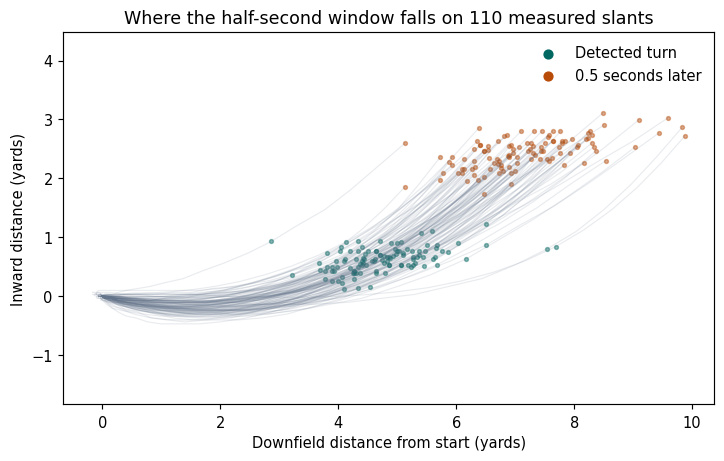

In [3]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for x, y, turn in paths:
    ax.plot(x[:turn + 6], y[:turn + 6], color="#64748b", alpha=.14, lw=.8)
    ax.scatter(x[turn], y[turn], s=7, color="#006761", alpha=.45)
    ax.scatter(x[turn+5], y[turn+5], s=7, color="#b84b08", alpha=.45)
for color, label in [("#006761", "Detected turn"), ("#b84b08", "0.5 seconds later")]:
    ax.scatter([], [], color=color, label=label)
ax.legend(frameon=False)
ax.set(xlabel="Downfield distance from start (yards)", ylabel="Inward distance (yards)",
       title=f"Where the half-second window falls on {len(paths)} measured slants")
ax.set_aspect("equal", adjustable="datalim")

fig.tight_layout()
plt.show()

*Figure 1. Each line is one left-slant attempt, aligned to its starting location. The two markers show where the speed comparison starts and ends. They identify a change of direction; an exact foot plant would require video.*

## 2. Compare the same receivers on the same NFL outcome
I use rookie regular-season routes against man coverage, including routes on which the receiver was never targeted. For each route, I subtract the typical separation for that route type in the 2023–24 data. A receiver’s outcome is their median remaining separation at pass release, measured in yards.

All three forecasts use the same 35 training receivers and the same 15 evaluation receivers at the primary 20-route cutoff. The first predicts the training average for everyone, the second adds dash time, and the third adds the slant measurement. Lower mean absolute error is better.

In [4]:
def game_routes(folder, wr):
    games = pd.read_csv(folder / "games.csv", usecols=["game_id", "season", "season_type"])
    reg = games.query("season_type == 'REG'")
    cols = ["game_id", "play_id", "nfl_id", "team_abbr", "possession_team", "route_ran",
            "team_coverage_man_zone", "play_nullified_by_penalty", "separation_at_pass_forward"]
    plays = pd.read_csv(folder / "player_play.csv", usecols=cols)
    plays = plays.merge(reg, on="game_id", validate="many_to_one").merge(
        wr[["nfl_id", "draft_year"]], on="nfl_id", validate="many_to_one")
    plays = plays.query("season == draft_year and team_abbr == possession_team and "
                        "team_coverage_man_zone == 'MAN_COVERAGE' and play_nullified_by_penalty == 'N'")
    plays = plays.dropna(subset=["route_ran", "separation_at_pass_forward"])
    plays = plays[plays.separation_at_pass_forward.ge(0)].copy()
    if plays.duplicated(["nfl_id", "game_id", "play_id"]).any():
        raise ValueError("Duplicate receiver-play records")
    # Centre separation by route type using earlier cohorts only.
    train = plays[plays.season < 2025]
    typical = train.groupby("route_ran").separation_at_pass_forward.median()
    plays["gap"] = plays.separation_at_pass_forward - plays.route_ran.map(typical)
    return plays.dropna(subset=["gap"]).groupby("nfl_id").gap.agg(
        routes="count", adjusted_gap="median").reset_index()


def forecast(train, test, features):
    def design(frame):
        return np.column_stack([np.ones(len(frame)), frame[features].to_numpy()])
    coef = np.linalg.lstsq(design(train), train.adjusted_gap, rcond=None)[0]
    return design(test) @ coef


def compare(data, minimum):
    eligible = data[data.routes >= minimum]
    train, test = eligible[eligible.draft_year < 2025], eligible[eligible.draft_year == 2025]
    if len(train) < 4 or len(test) < 2:
        raise ValueError("Insufficient eligible players")
    errors = np.array([abs(test.adjusted_gap - forecast(train, test, features)).to_numpy()
                       for features in ([], ["forty"], ["forty", "gain"])])
    difference = errors[1] - errors[2]
    rng = np.random.default_rng(2027)
    interval = np.quantile(rng.choice(difference, (5000, len(test)), replace=True).mean(axis=1),
                           [0.025, 0.975])
    print(f"{minimum} routes | train {len(train)}, test {len(test)} | "
          f"MAE {errors.mean(axis=1).round(4)} | dash minus combined "
          f"{difference.mean():+.4f}, interval {interval.round(4)}")
    return errors.mean(axis=1), len(test)



wr = pd.read_csv(folder / 'combine_results.csv').query("combine_position == 'WR'")
data = wr.merge(features, on=['nfl_id', 'draft_year'], validate='one_to_one')
data = data.merge(game_routes(folder, wr), on='nfl_id', validate='one_to_one').dropna(subset=['forty'])
for minimum in (10, 20, 30):
    errors, n = compare(data, minimum)
    if minimum == 20:
        scores, test_size = errors, n

10 routes | train 43, test 16 | MAE [0.1453 0.1972 0.1977] | dash minus combined -0.0005, interval [-0.0022  0.0016]
20 routes | train 35, test 15 | MAE [0.1346 0.1618 0.1748] | dash minus combined -0.0130, interval [-0.0356  0.0109]
30 routes | train 32, test 14 | MAE [0.1387 0.1675 0.1726] | dash minus combined -0.0051, interval [-0.0234  0.0144]


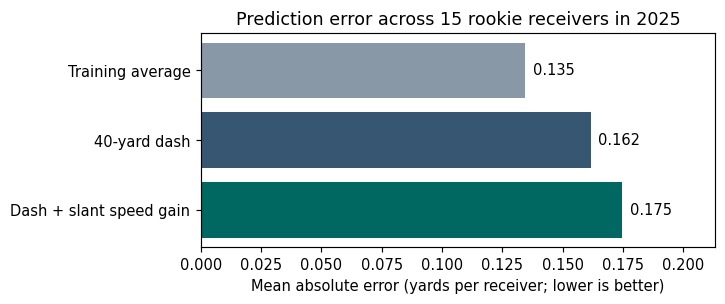

In [5]:
fig, ax = plt.subplots(figsize=(7, 3))
labels = ["Training average", "40-yard dash", "Dash + slant speed gain"]
bars = ax.barh(labels, scores, color=["#8998a6", "#375672", "#006761"])
ax.invert_yaxis()
ax.bar_label(bars, fmt="%.3f", padding=5)
ax.set_xlim(0, max(scores)*1.22)
ax.set(title=f"Prediction error across {test_size} rookie receivers in 2025",
       xlabel="Mean absolute error (yards per receiver; lower is better)")

fig.tight_layout()
plt.show()

*Figure 2. On 2025 rookies with at least 20 qualifying routes, the training average had the lowest error (0.135 yards). At minimums of 10 and 30 routes, adding slant speed gain also failed to improve on dash time.*

## What a scout can take away
A small speed gain can mean two different things: the receiver was slow to accelerate, or the receiver carried so much speed through the break that little recovery was necessary. I’d review film of receivers with similar dash times and compare their entry and exit speeds before treating this measurement as a draft grade.

## How much confidence should we place in the result?
The estimated gain in accuracy from adding the slant metric was **−0.013 yards**. Its approximate 95% interval ran from **−0.036 to +0.011 yards**, resampling the 15 evaluation players with the training models fixed. Pre-snap cushion, defender quality and release timing could also affect separation. The 2025 cohort was examined in an earlier dash-time study, so a new draft class would be a stronger independent check.

[Reproducible Python script and standalone figures](https://github.com/maybesmdieko/NFL-BDB-Analysis/tree/main/slant)